# Exploration de la source NewsAPI

## 1. Contexte et objectif du notebook

Après OpenSky et OpenWeather, j'explore la troisième et dernière source du projet : NewsAPI, qui donne accès à des articles de presse récents via mots-clés (`https://newsapi.org/v2/everything`), après avoir lu la documentation de l'API (`https://newsapi.org/docs`).

L'idée derrière cette source est différente des deux premières : il ne s'agit pas d'une mesure physique (position d'avion, météo), mais d'un signal textuel destiné à capter des événements pouvant perturber le trafic aérien — grèves, conditions météo extrêmes, perturbations du contrôle aérien, incidents aéroportuaires — sur les dix hubs européens déjà utilisés pour OpenWeather.

Le module d'ingestion (`src/ingestion/newsapi_client.py`) interroge cinq requêtes mots-clés prédéfinies, une par langue (français, anglais, allemand, espagnol, italien), plutôt qu'une collecte exhaustive : le plan gratuit de NewsAPI limite à la fois la fenêtre temporelle interrogeable (environ les 30 derniers jours) et le nombre d'appels quotidiens (100 requêtes/jour).

Je veux répondre à la question  pour combien de langues différentes ces articles se répartissent-ils réellement, et dans quelle proportion pour chacune ? J'explore aussi la volumétrie, la fraîcheur des articles, la complétude des champs (en particulier `content`, réputé tronqué sur le plan gratuit), les sources représentées, et les doublons éventuels entre requêtes.

Comme pour les deux sources précédentes, ces résultats ne sont pas figés : relancer ce notebook plus tard interrogera de nouveaux articles publiés depuis, et pourra donner des chiffres différents.

In [1]:
import glob
import json
import os
import re
import sys
import warnings
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd

RACINE_PROJET = os.path.abspath(os.path.join(os.getcwd(), ".."))
if RACINE_PROJET not in sys.path:
    sys.path.insert(0, RACINE_PROJET)
os.chdir(RACINE_PROJET)

from src.ingestion.newsapi_client import NewsApiClient
from src.utils.chemins import chemin_relatif_projet

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

## 2. Récupération et chargement des données

J'interroge le module d'ingestion actualités pour les cinq requêtes mots-clés/langue définies dans `REQUETES_ACTUALITES` (français, anglais, allemand, espagnol, italien) : cinq appels HTTP au total pour cette capture, bien en dessous du quota de 100 requêtes/jour du plan gratuit.

J'appelle l'API NewsAPI en direct, puis je sauvegarde le résultat dans `data/raw/` (fichier JSON horodaté, non versionné), comme pour les deux sources précédentes. En cas d'erreur (quota dépassé, clé invalide), je retombe sur le dernier fichier déjà collecté, pour que le notebook reste exécutable même hors connexion.

In [2]:
DOSSIER_DONNEES_BRUTES = os.path.join(RACINE_PROJET, "data", "raw")

try:
    client = NewsApiClient()
    donnees_brutes = client.recuperer_actualites_aeroportuaires()
    chemin_fichier = client.sauvegarder_donnees_brutes(
        donnees_brutes, dossier=DOSSIER_DONNEES_BRUTES
    )
    print(f"Nouvel appel API réussi, données sauvegardées dans : {chemin_relatif_projet(chemin_fichier)}")
except Exception as erreur:
    print(f"Appel API impossible ({erreur}), réutilisation du dernier fichier disponible.")
    fichiers_disponibles = sorted(
        glob.glob(os.path.join(DOSSIER_DONNEES_BRUTES, "newsapi_*.json"))
    )
    chemin_fichier = fichiers_disponibles[-1]
    with open(chemin_fichier, encoding="utf-8") as fichier:
        donnees_brutes = json.load(fichier)
    print(f"Fichier réutilisé : {chemin_relatif_projet(chemin_fichier)}")

print(f"Horodatage de la collecte : {donnees_brutes['horodatage_collecte']}")
print(f"Nombre de requêtes effectuées : {len(donnees_brutes['requetes'])}")
print()
for requete in donnees_brutes["requetes"]:
    nb_recus = len(requete["resultat"].get("articles", []))
    total_disponible = requete["resultat"].get("totalResults")
    print(
        f"  - langue={requete['langue_requete']:3s} "
        f"articles reçus={nb_recus:3d}  totalResults annoncé par l'API={total_disponible}"
    )

2026-08-25 15:50:47,835 - src.ingestion.newsapi_client - INFO - Récupération des actualités pour la requête '"grève aéroport" OR "grève transport aérien" OR "contrôle aérien" OR "trafic aérien perturbé"' (langue : fr).
2026-08-25 15:50:48,429 - src.ingestion.newsapi_client - INFO - Appel à l'API NewsAPI réussi (code 200).
2026-08-25 15:50:48,433 - src.ingestion.newsapi_client - INFO - Récupération des actualités pour la requête '"airport strike" OR "flight delay" OR "air traffic control" OR "airspace closure"' (langue : en).
2026-08-25 15:50:49,056 - src.ingestion.newsapi_client - INFO - Appel à l'API NewsAPI réussi (code 200).
2026-08-25 15:50:49,060 - src.ingestion.newsapi_client - INFO - Récupération des actualités pour la requête '"Flughafen Streik" OR "Flugverspätung" OR "Fluglotsen Streik"' (langue : de).
2026-08-25 15:50:49,551 - src.ingestion.newsapi_client - INFO - Appel à l'API NewsAPI réussi (code 200).
2026-08-25 15:50:49,554 - src.ingestion.newsapi_client - INFO - Récupéra

Nouvel appel API réussi, données sauvegardées dans : data/raw/newsapi_20260825_155050.json
Horodatage de la collecte : 2026-08-25T15:50:50.575960
Nombre de requêtes effectuées : 5

  - langue=fr  articles reçus=  8  totalResults annoncé par l'API=8
  - langue=en  articles reçus= 96  totalResults annoncé par l'API=334
  - langue=de  articles reçus=  6  totalResults annoncé par l'API=6
  - langue=es  articles reçus=  0  totalResults annoncé par l'API=0
  - langue=it  articles reçus= 10  totalResults annoncé par l'API=10


## 3. Combien d'articles obtient-on, et à quoi ressemblent les données une fois mises à plat ?

Chaque requête renvoie un objet JSON avec une liste `articles`. Je regroupe les articles de mes cinq requêtes en une seule ligne par article, en conservant la langue et les mots-clés de la requête qui l'a renvoyé, pour obtenir un DataFrame directement exploitable.

In [3]:
lignes_articles = []
for requete in donnees_brutes["requetes"]:
    for article in requete["resultat"].get("articles", []):
        ligne = dict(article)
        ligne["source_nom"] = (article.get("source") or {}).get("name")
        ligne["langue_requete"] = requete["langue_requete"]
        ligne["mots_cles_requete"] = requete["mots_cles"]
        lignes_articles.append(ligne)

df_articles = pd.DataFrame(lignes_articles).drop(columns=["source"])

colonnes_identification = ["langue_requete", "source_nom", "title", "publishedAt"]
colonnes_ordonnees = colonnes_identification + [
    colonne for colonne in df_articles.columns if colonne not in colonnes_identification
]
df_articles = df_articles[colonnes_ordonnees]

print(f"Nombre de lignes (articles) : {len(df_articles)}")
print(f"Nombre de colonnes : {df_articles.shape[1]}")
df_articles.head(10)

Nombre de lignes (articles) : 120
Nombre de colonnes : 10


,langue_requete,source_nom,title,publishedAt,author,description,url,urlToImage,content,mots_cles_requete
0,fr,Gameblog,"En plein vol, un pilote de Rafale détecte une fuite de kérosène sur un jet p...",2026-08-23T05:30:00Z,Mathilde,"Une simple traînée de fumée trop fine, et un pilote de Rafale évite le pire ...",https://www.gameblog.fr/trends/en-plein-vol-un-pilote-de-rafale-detecte-une-...,https://cdn-uploads.gameblog.fr/img//_6a8a1f2eb40a1.webp,"Une simple traînée de fumée trop fine, et un pilote de Rafale évite le pire ...","""grève aéroport"" OR ""grève transport aérien"" OR ""contrôle aérien"" OR ""trafic..."
1,fr,Gameblog,Les deux pilotes d'un A320 s'endorment à 36 000 pieds avec 153 passagers : l...,2026-08-23T05:00:00Z,Mathilde,"159 passagers, deux pilotes endormis, un avion livré à lui-même pendant 28 m...",https://www.gameblog.fr/trends/les-deux-pilotes-dun-a320-sendorment-a-36-000...,https://cdn-uploads.gameblog.fr/img//_6a8a1e7920fee.webp,"159 passagers, deux pilotes endormis, un avion livré à lui-même pendant 28 m...","""grève aéroport"" OR ""grève transport aérien"" OR ""contrôle aérien"" OR ""trafic..."
2,fr,Journal du geek,"Aux États-Unis, les contrôleurs aériens se recrutent chez les joueurs",2026-08-17T07:00:35Z,Olivier,Le ministère américain des Transports a lancé une campagne pour attirer les ...,https://www.journaldugeek.com/2026/08/17/aux-etats-unis-les-controleurs-aeri...,https://www.journaldugeek.com/app/uploads/2025/09/aeroport-cyberattaque-1600...,Et si toutes ces heures passées à construire des tours dans Fortnite finissa...,"""grève aéroport"" OR ""grève transport aérien"" OR ""contrôle aérien"" OR ""trafic..."
3,fr,dh.be,Le trafic aérien perturbé en Europe: un aéroport allemand survolé par un dro...,2026-08-11T16:45:28Z,Belga Belga,"L'aéroport allemand de Hanovre a été survolé par un drone inconnu, ce qui a ...",https://www.dhnet.be/actu/monde/2026/08/11/le-trafic-aerien-perturbe-en-euro...,https://www.dhnet.be/resizer/v2/MOZQCLD2D5GD7LRZV7VU6L6GQE.jpg?auth=0b570075...,"""L'enquête sur le survol d'un drone à l'aéroport de Langenhagen mardi a été ...","""grève aéroport"" OR ""grève transport aérien"" OR ""contrôle aérien"" OR ""trafic..."
4,fr,PRNewswire,DeTect remporte un contrat pour la fourniture de radars de détection d'oisea...,2026-08-11T05:20:00Z,None,Le système de sécurité aérienne par radars de détection des oiseaux renforce...,https://www.prnewswire.com/news-releases/detect-remporte-un-contrat-pour-la-...,https://mmx.prnewswire.com/media/MS1965904/MERLIN-True3D-Night.jpg?id=OA2834...,Le système de sécurité aérienne par radars de détection des oiseaux renforce...,"""grève aéroport"" OR ""grève transport aérien"" OR ""contrôle aérien"" OR ""trafic..."
5,fr,Franceinfo.fr,Deux avions de ligne évitent de peu une collision à l'aéroport de Sydney,2026-08-09T09:26:32Z,None,Un membre d'équipage a été blessé et quelques dégâts ont été constaté. Une e...,https://www.franceinfo.fr/economie/aeronautique/deux-avions-de-ligne-evitent...,https://www.franceinfo.fr/pictures/aUYHpFREP6kNk8xSNEiAcZJpudo/0x106:1024x68...,Le drame a été frôlé. Une collision entre deux avions de ligne sur le tarmac...,"""grève aéroport"" OR ""grève transport aérien"" OR ""contrôle aérien"" OR ""trafic..."
6,fr,Lavenir.net,Australie: deux avions de ligne évitent de peu une collision à l'aéroport de...,2026-08-09T05:37:53Z,Belga Belga,Le régulateur australien de la sécurité des transports a annoncé l'ouverture...,https://www.lavenir.net/actu/monde/2026/08/09/australie-deux-avions-de-ligne...,https://www.lavenir.net/resizer/v2/C7G27IH5VZAMHDHTHB4YN22NPM.jpg?auth=2e6f2...,Une photo publiée par les médias locaux montre les deux appareils sur le tar...,"""grève aéroport"" OR ""grève transport aérien"" OR ""contrôle aérien"" OR ""trafic..."
7,fr,Le Dauphiné Libéré,Alpes-de-Haute-Provence. Crash de la Germanwings : l'Allemagne attaquée en j...,2026-08-03T16:59:00Z,Sylvain Jolivet,"Le 24 mars 2015, le crash de l’Airbus A320 de la Germanwi

**Observations** : cette capture donne 120 lignes (articles) et 10 colonnes. On retrouve la structure documentée par NewsAPI : `title`, `description`, `content` (tronqué, voir plus bas), `url`, `urlToImage`, `publishedAt`, `author`, le nom de la source aplati dans `source_nom`, et les deux colonnes ajoutées lors de la mise à plat (`langue_requete`, `mots_cles_requete`) pour tracer la requête d'origine de chaque article.

## 4. Quelle est la répartition par langue des articles récupérés ?

C'est le point central de cette exploration : l'endpoint `/v2/everything` ne renvoie aucun champ indiquant la langue détectée d'un article, mais le paramètre `language` de chaque requête filtre déjà les résultats côté serveur. Je peux donc mesurer la répartition par langue directement à partir de la langue demandée par chacune de mes cinq requêtes (`langue_requete`), sans avoir besoin d'un détecteur de langue supplémentaire sur le texte.

Nombre de langues distinctes ayant renvoyé au moins un article : 4 sur 5 demandées

Répartition par langue (nombre d'articles) :
langue_requete
en    96
it    10
fr     8
de     6
Name: count, dtype: int64

Répartition par langue (% du total) :
langue_requete
en    80.0
it     8.3
fr     6.7
de     5.0
Name: count, dtype: float64


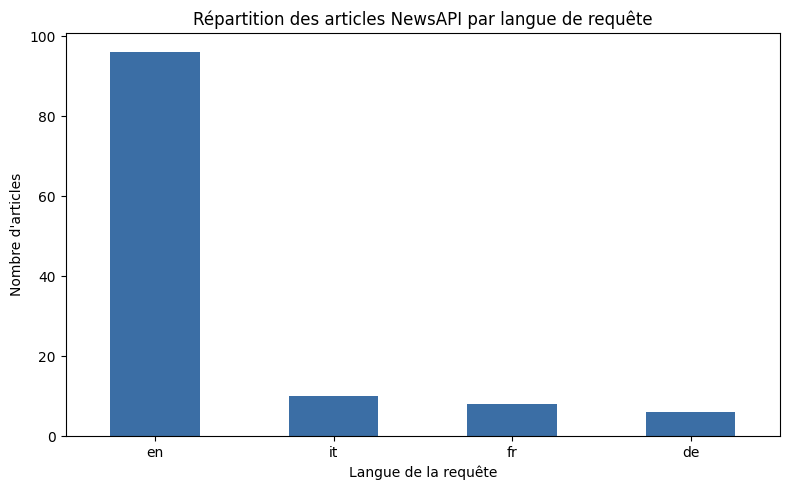

In [4]:
repartition_langue = df_articles["langue_requete"].value_counts()
repartition_langue_pct = (repartition_langue / len(df_articles) * 100).round(1)

print(f"Nombre de langues distinctes ayant renvoyé au moins un article : {repartition_langue.shape[0]} sur 5 demandées")
print()
print("Répartition par langue (nombre d'articles) :")
print(repartition_langue)
print()
print("Répartition par langue (% du total) :")
print(repartition_langue_pct)

fig, ax = plt.subplots(figsize=(8, 5))
repartition_langue.plot(kind="bar", ax=ax, color="#3b6ea5")
ax.set_xlabel("Langue de la requête")
ax.set_ylabel("Nombre d'articles")
ax.set_title("Répartition des articles NewsAPI par langue de requête")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observations** : sur les cinq langues demandées, quatre ont renvoyé au moins un article (français, anglais, allemand, italien) ; la requête espagnole n'a renvoyé aucun résultat sur cette capture. L'anglais domine très largement avec 96 articles (80 % du total), loin devant l'italien (10 articles, 8,3 %), le français (8 articles, 6,7 %) et l'allemand (6 articles, 5 %).

Ce déséquilibre s'explique en partie par la couverture de presse internationale bien plus large en anglais sur ce type de sujet (grèves, ATC, incidents), et en partie par le plafond de 100 articles par requête du plan gratuit : la requête anglaise annonce un `totalResults` bien supérieur à 96, alors que les quatre autres langues renvoient la totalité de ce qui existe réellement sur la fenêtre de 30 jours.

Cette répartition très déséquilibrée est un constat factuel à retenir pour le choix futur d'un modèle BERT de sentiment : un corpus composé à 80 % d'anglais poserait la question de la pertinence d'un modèle monolingue anglais complété au cas par cas, par rapport à un modèle multilingue unique — ce choix n'est pas tranché ici, seule la distribution est documentée.

## 5. Quelle est la fraîcheur des articles récupérés ?

Le champ `publishedAt` indique la date et l'heure de publication de l'article (UTC). Je calcule l'écart entre cette date et l'instant de ma collecte (`horodatage_collecte`), pour vérifier concrètement la fenêtre de 30 jours annoncée par NewsAPI pour le plan gratuit. Le parsing ci-dessous accepte à la fois les fichiers raw déjà collectés (horodatage sans fuseau) et les collectes suivantes (horodatage UTC).

In [5]:
instant_collecte = datetime.fromisoformat(donnees_brutes["horodatage_collecte"])
if instant_collecte.tzinfo is None:
    # Fichiers raw déjà collectés : horodatage sans fuseau, lu comme UTC
    instant_collecte_utc = instant_collecte.replace(tzinfo=timezone.utc)
else:
    instant_collecte_utc = instant_collecte.astimezone(timezone.utc)

df_articles["publishedAt"] = pd.to_datetime(df_articles["publishedAt"], utc=True)
df_articles["age_article_jours"] = (
    instant_collecte_utc - df_articles["publishedAt"]
).dt.total_seconds() / 86400

print("Distribution de l'âge des articles (en jours) :")
print(df_articles["age_article_jours"].describe())
print()
print(f"Article le plus ancien : {df_articles['publishedAt'].min()}")
print(f"Article le plus récent : {df_articles['publishedAt'].max()}")

Distribution de l'âge des articles (en jours) :
count    120.000000
mean       6.798798
std        5.841816
min        1.147136
25%        3.624495
50%        5.117460
75%        7.234075
max       29.426176
Name: age_article_jours, dtype: float64

Article le plus ancien : 2026-07-27 05:37:09+00:00
Article le plus récent : 2026-08-24 12:18:58+00:00


**Observations** : sur cette capture, les articles ont entre 1,1 et 29,3 jours d'ancienneté (moyenne autour de 6,8 jours), ce qui confirme concrètement la limite du plan gratuit NewsAPI : impossible de récupérer un article publié il y a plus d'environ un mois. C'est très différent de la fraîcheur observée sur OpenSky (secondes) et OpenWeather (dizaines de secondes) : NewsAPI n'a pas vocation à donner un signal temps réel, mais un historique glissant sur un mois, ce qui est cohérent avec son usage prévu (contexte d'actualité autour d'une période donnée, pas événement instantané).

**Point observé sur les horodatages** : `publishedAt` est bien renvoyé en UTC par NewsAPI. En revanche, le tampon `horodatage_collecte` des fichiers raw déjà collectés a été généré en heure locale naïve (UTC+2 l'été sur cette machine), sans indication de fuseau. En lisant cette chaîne comme si elle était déjà UTC, le calcul d'âge se retrouve biaisé d'environ deux heures. Le module d'ingestion produit désormais un horodatage UTC. Sur un âge moyen d'environ 6,8 jours, ce biais d'environ 2 h reste limité et ne change pas les conclusions de cette exploration (fenêtre d'un mois confirmée, pas de signal temps réel). Le parsing ci-dessus reste compatible avec les deux formats : fichiers déjà collectés (heure naïve) et collectes suivantes (UTC).

## 6. Quels champs sont complets, et le champ `content` est-il vraiment tronqué ?

Je calcule le taux de complétude de chaque colonne, puis je vérifie spécifiquement le champ `content` : NewsAPI documente une limitation du plan gratuit qui tronque ce champ à 200 caractères environ, avec un suffixe du type `[+N chars]` indiquant le nombre de caractères manquants.

In [6]:
colonnes_a_verifier = ["title", "description", "content", "author", "urlToImage"]
taux_completude = (df_articles[colonnes_a_verifier].notna().mean() * 100).sort_values()
print("Taux de complétude par colonne (%) :")
print(taux_completude.round(1))

print()
motif_troncature = re.compile(r"\[\+\d+ chars\]$")
contents_non_nuls = df_articles["content"].dropna()
nb_tronques = contents_non_nuls.str.contains(motif_troncature).sum()
longueurs_content = contents_non_nuls.str.len()

print(f"Articles avec un champ 'content' tronqué (suffixe '[+N chars]') : {nb_tronques} / {len(contents_non_nuls)}")
print(f"Longueur de 'content' - min : {longueurs_content.min()}, max : {longueurs_content.max()}, moyenne : {longueurs_content.mean():.1f}")

Taux de complétude par colonne (%) :
author          90.0
urlToImage      97.5
title          100.0
description    100.0
content        100.0
dtype: float64

Articles avec un champ 'content' tronqué (suffixe '[+N chars]') : 120 / 120
Longueur de 'content' - min : 212, max : 215, moyenne : 213.9


**Observations** : `title`, `description` et `content` sont complets à 100 % sur cette capture ; seuls `author` (environ 90 % de complétude) et `urlToImage` (environ 97,5 %) manquent occasionnellement, ce qui reste marginal.

La limitation documentée par NewsAPI se confirme intégralement : les 120 articles de cette capture ont tous un champ `content` tronqué au format `[+N chars]`, avec une longueur quasi constante d'environ 214 caractères, bien loin du texte complet de l'article. Concrètement, `content` n'est donc pas exploitable tel quel comme texte source pour l'analyse de sentiment prévue en Phase 2.

Seuls `title` et `description`, qui eux sont fournis en entier, constituent une base de texte fiable pour un futur modèle BERT (dans le périmètre de ce projet).

La complétude ne dit rien de la qualité du texte lui-même. Les articles arrivent ici en quatre langues, avec accents, diacritiques et ponctuation typographique : c'est la source la plus exposée à un problème d'encodage, et un titre mal décodé se retrouverait tel quel dans toute analyse de texte ultérieure. Je cherche donc les séquences de mojibake caractéristiques d'un texte UTF-8 relu en Latin-1 (`Ã©`, `Ã¨`, `Ã `, `Ãª`, `Ã¼`, `Ã§`, `â€`) ainsi que le caractère de remplacement U+FFFD, puis j'affiche un titre accentué par langue demandée comme preuve visuelle.

In [7]:
MOTIFS_MOJIBAKE = ("Ã©", "Ã¨", "Ã ", "Ãª", "Ã¼", "Ã§", "â€", "\ufffd")

for colonne in ("title", "description", "author", "source_nom"):
    valeurs = df_articles[colonne].dropna()
    nb_mojibake = valeurs.apply(
        lambda texte: any(motif in texte for motif in MOTIFS_MOJIBAKE)
    ).sum()
    nb_accentuees = valeurs.apply(lambda texte: not texte.isascii()).sum()
    print(
        f"{colonne} : {nb_mojibake} valeur(s) portant un motif de mojibake sur "
        f"{len(valeurs)} valeur(s) non nulle(s), {nb_accentuees} contenant des caractères accentués"
    )

print()
print("Exemple de titre accentué pour chaque langue demandée :")
for langue in ("fr", "en", "de", "es", "it"):
    titres = df_articles.loc[df_articles["langue_requete"] == langue, "title"].dropna()
    titres_accentues = titres[titres.apply(lambda texte: not texte.isascii())]
    if titres_accentues.empty:
        print(f"  {langue} : aucun titre accentué ({len(titres)} article(s) dans cette langue)")
    else:
        print(f"  {langue} : {titres_accentues.iloc[0][:95]}")

title : 0 valeur(s) portant un motif de mojibake sur 120 valeur(s) non nulle(s), 29 contenant des caractères accentués
description : 0 valeur(s) portant un motif de mojibake sur 120 valeur(s) non nulle(s), 65 contenant des caractères accentués
author : 0 valeur(s) portant un motif de mojibake sur 108 valeur(s) non nulle(s), 3 contenant des caractères accentués
source_nom : 0 valeur(s) portant un motif de mojibake sur 120 valeur(s) non nulle(s), 2 contenant des caractères accentués

Exemple de titre accentué pour chaque langue demandée :
  fr : En plein vol, un pilote de Rafale détecte une fuite de kérosène sur un jet privé : « il contrib
  en : 90 Times People’s Trips Didn’t Go Exactly As Planned
  de : Prozess in München: Muss ein Reiseveranstalter bei späterem Abflug einen Urlaubstag erstatten?
  es : aucun titre accentué (0 article(s) dans cette langue)
  it : “C’è un incendio in cabina nella parte posteriore dell’aereo”: paura sul volo American Airlines


**Observations** : aucun motif de mojibake, sur aucune des quatre colonnes de texte. Les caractères accentués sont bien présents là où on les attend : 29 titres sur 120 et 65 descriptions sur 120 en contiennent, ainsi que 3 auteurs sur 108 et 2 noms de source. Les exemples affichés le confirment langue par langue : « détecte une fuite de kérosène » en français, l'apostrophe typographique de « People’s » rendue comme telle et non en « â€™ » en anglais, « München » et « späterem » en allemand, « C’è un incendio » en italien.

La requête espagnole n'ayant renvoyé aucun article sur cette capture, cette langue reste non contrôlée : le motif `Ã³`, très fréquent en espagnol, sera à ajouter à la liste dès qu'une capture en ramènera.

Le décodage UTF-8 est donc correct de bout en bout, de la réponse HTTP au fichier JSON relu par ce notebook. `title` et `description` sont exploitables directement comme texte source, sans étape de réparation d'encodage — ce qui compte d'autant plus qu'ils constituent, comme vu juste au-dessus, la seule base de texte complète de cette source.

Ces deux champs sont extraits par NewsAPI depuis les pages des médias, et ce type d'extraction laisse souvent passer des fragments de balisage : balises ouvrantes ou fermantes, entités HTML non converties. Je vérifie aussi que les URL d'article et d'image sont bien formées, puisque l'URL sert d'identifiant de l'article dans toute la suite du pipeline.

In [8]:
BALISES_HTML = ("<p>", "<br", "<a ", "</", "&nbsp;", "&amp;", "&quot;", "&#")

for colonne in ("title", "description"):
    valeurs = df_articles[colonne].dropna()
    nb_html = valeurs.apply(
        lambda texte: any(balise in texte for balise in BALISES_HTML)
    ).sum()
    print(f"{colonne} : {nb_html} valeur(s) contenant une balise ou une entité HTML résiduelle")

print()
SCHEMAS_VALIDES = ("http://", "https://")
urls_article = df_articles["url"].dropna()
urls_image = df_articles["urlToImage"].dropna()

print(f"URL d'article renseignées : {len(urls_article)}")
print(f"  dont ne commençant pas par http:// ou https:// : {(~urls_article.str.startswith(SCHEMAS_VALIDES)).sum()}")
print(f"  dont contenant un espace : {urls_article.str.contains(' ').sum()}")
print(f"URL d'image renseignées : {len(urls_image)}")
print(f"  dont ne commençant pas par http:// ou https:// : {(~urls_image.str.startswith(SCHEMAS_VALIDES)).sum()}")

title : 0 valeur(s) contenant une balise ou une entité HTML résiduelle
description : 0 valeur(s) contenant une balise ou une entité HTML résiduelle

URL d'article renseignées : 120
  dont ne commençant pas par http:// ou https:// : 0
  dont contenant un espace : 0
URL d'image renseignées : 117
  dont ne commençant pas par http:// ou https:// : 0


**Observations** : aucune balise ni entité HTML résiduelle dans les 120 titres et les 120 descriptions, et aucune URL mal formée — les 120 URL d'article et les 117 URL d'image renseignées commencent toutes par un schéma valide et ne contiennent aucun espace.

NewsAPI livre donc un texte déjà nettoyé côté fournisseur, et aucune étape de dé-balisage n'est nécessaire avant l'analyse textuelle. Le contrôle reste utile comme garde-fou : l'ensemble de sources couvert varie d'une requête à l'autre, et rien ne garantit que toutes soient aussi propres que celles rencontrées ici.

## 7. Quelles sont les sources et les domaines représentés ?

Je regarde combien de sources distinctes apparaissent dans cette capture, et lesquelles reviennent le plus souvent.

In [9]:
nb_sources_distinctes = df_articles["source_nom"].nunique()
print(f"Nombre de sources/domaines distincts : {nb_sources_distinctes}")
print()
print("Top 10 des sources les plus représentées :")
print(df_articles["source_nom"].value_counts().head(10))

Nombre de sources/domaines distincts : 73

Top 10 des sources les plus représentées :
source_nom
Crypto Briefing         9
The Times of India      7
Fox News                4
Biztoc.com              4
BBC News                4
Dailymail.com           4
Ilfattoquotidiano.it    3
Khabarhub.com           3
CNA                     3
BusinessLine            3
Name: count, dtype: int64


**Observations** : 73 sources distinctes apparaissent sur 120 articles, un éparpillement assez fort qui montre que la requête ne se concentre pas sur quelques gros médias mais couvre un tissu de presse large. Aucune source ne domine franchement (la plus fréquente n'apparaît que 9 fois).

En consultant le détail des titres de la source la plus fréquente, j'ai repéré une limite concrète de la recherche par mots-clés : plusieurs articles proviennent en réalité de tensions géopolitiques au Moyen-Orient (fermetures d'espace aérien liées à des tensions militaires), remontés par le mot-clé anglais `"airspace closure"` alors qu'ils n'ont aucun rapport avec des perturbations de trafic commercial.

Cela montre une limite de la recherche par mots-clés génériques : un filtrage supplémentaire par pertinence (ou un raffinement des mots-clés) sera à prévoir en Phase 2 avant d'utiliser ce texte comme feature de sentiment.


## 8. Y a-t-il des doublons d'articles entre les différentes requêtes mots-clés ?

Comme je fais cinq requêtes distinctes, le même article pourrait en théorie être renvoyé par plusieurs requêtes (par exemple un article multilingue indexé sous deux langues, ou un même événement couvert par des mots-clés qui se recoupent). Je vérifie ce point sur l'URL de l'article, qui identifie chaque article de façon unique.

In [10]:
nb_urls_distinctes = df_articles["url"].nunique()
nb_doublons = len(df_articles) - nb_urls_distinctes

print(f"Nombre total d'articles : {len(df_articles)}")
print(f"Nombre d'URL distinctes : {nb_urls_distinctes}")
print(f"Nombre de doublons (URL apparue plus d'une fois) : {nb_doublons}")

if nb_doublons > 0:
    urls_dupliquees = df_articles["url"].value_counts()
    urls_dupliquees = urls_dupliquees[urls_dupliquees > 1]
    print()
    print("Détail des URL dupliquées et des langues de requête associées :")
    print(df_articles[df_articles["url"].isin(urls_dupliquees.index)][["url", "langue_requete"]])

Nombre total d'articles : 120
Nombre d'URL distinctes : 120
Nombre de doublons (URL apparue plus d'une fois) : 0


**Observations** : aucun doublon d'URL sur cette capture, les 120 articles sont tous distincts. C'est cohérent avec la conception des requêtes : chaque requête combine des mots-clés dans une langue précise (`language=fr`, `language=en`...), et NewsAPI ne renvoie a priori que des sources publiées dans cette langue pour ce paramètre, ce qui limite fortement le risque de chevauchement entre mes cinq requêtes. Ce constat n'est pas garanti pour toute capture future : si les mots-clés se recoupaient davantage d'une langue à l'autre (agences de presse publiant le même article traduit), une déduplication par URL resterait une précaution à prévoir systématiquement en Phase 2.

L'unicité des URL ne suffit pas à conclure sur les doublons : deux URL différentes peuvent parfaitement pointer vers le même article, qu'il soit republié par un agrégateur ou servi par le même média sous deux domaines. Je complète donc le contrôle précédent par une comparaison sur le titre normalisé, passé en minuscules et débarrassé de sa ponctuation.

In [11]:
titres_normalises = (
    df_articles["title"].str.lower().str.replace(r"[^\w]+", " ", regex=True).str.strip()
)
nb_titres_distincts = titres_normalises.nunique()
nb_doublons_titre = len(df_articles) - nb_titres_distincts

print(f"Titres normalisés distincts : {nb_titres_distincts} sur {len(df_articles)} articles")
print(f"Doublons sur titre normalisé : {nb_doublons_titre}")

if nb_doublons_titre:
    titres_repetes = titres_normalises.value_counts()
    titres_repetes = titres_repetes[titres_repetes > 1]
    print()
    print(
        df_articles.loc[
            titres_normalises.isin(titres_repetes.index),
            ["langue_requete", "source_nom", "title", "url"],
        ].sort_values("title")
    )

Titres normalisés distincts : 113 sur 120 articles
Doublons sur titre normalisé : 7

   langue_requete           source_nom  \
13             en             Fox News   
14             en             Fox News   
47             en                  CNA   
48             en                  CNA   
50             en  Yahoo Entertainment   
51             en           Biztoc.com   
58             en         BusinessLine   
59             en         BusinessLine   
31             en           Biztoc.com   
32             en             BBC News   
15             en             BBC News   
16             en             BBC News   

                                                                              title  \
13  American Airlines flight lands safely after laptop battery catches fire on b...   
14  American Airlines flight lands safely after laptop battery catches fire on b...   
47  Australia investigates fourth close call at Sydney airport in less than a month   
48  Australia invest

**Observations** : 113 titres normalisés distincts pour 120 articles, soit 7 doublons que le contrôle par URL ne voyait pas, puisque chacune de ces lignes porte bien une URL différente.

Les cas se lisent directement dans l'extrait : le quasi-accident de l'aéroport de Sydney apparaît quatre fois (deux URL du même média, une reprise par un portail, une par un agrégateur), l'incendie de batterie d'ordinateur portable à bord apparaît deux fois sous le titre d'un média américain et deux fois sous celui de la BBC dont une reprise par un agrégateur, la baisse du trafic aérien domestique est publiée deux fois sur deux rubriques du même site, et un article est servi à la fois sur le domaine `.com` et le domaine `.co.uk` du même média.

Tous ces doublons proviennent de la requête anglaise, la seule à ramener assez d'articles pour que le phénomène apparaisse.

Conséquence pour la suite : une déduplication par URL est insuffisante, il faudra tester de dédupliquer sur le titre normalisé : un même événement qui serait compté plusieurs fois pourrait gonfler artificiellement le signal d'actualité associé à une journée.

## 9. Quel volume de données cela représente-t-il ?

Je calcule la taille du fichier JSON de cette capture, puis je projette le volume sur la durée du projet, en tenant compte cette fois de la contrainte propre à NewsAPI : ce n'est pas la fréquence de collecte qui limite le volume (comme pour OpenSky/OpenWeather), mais le quota fixe de 100 requêtes par jour, soit au maximum 20 collectes de cinq requêtes par jour.

In [12]:
taille_octets = os.path.getsize(chemin_fichier)
taille_ko = taille_octets / 1024

print(f"Nombre d'articles de cette capture : {len(df_articles)}")
print(f"Taille du fichier JSON brut : {taille_octets} octets ({taille_ko:.1f} Ko)")
print()

REQUETES_PAR_COLLECTE = 5
QUOTA_REQUETES_JOUR = 100
nb_collectes_max_par_jour = QUOTA_REQUETES_JOUR // REQUETES_PAR_COLLECTE
DUREE_COLLECTE_JOURS = 14

print(f"Nombre maximal de collectes complètes par jour (quota de {QUOTA_REQUETES_JOUR} requêtes/jour) : {nb_collectes_max_par_jour}")
for nb_collectes_jour in (1, 4, nb_collectes_max_par_jour):
    volume_total_mo = nb_collectes_jour * DUREE_COLLECTE_JOURS * taille_octets / (1024 * 1024)
    print(
        f"  - {nb_collectes_jour} collecte(s)/jour sur deux semaines : "
        f"environ {volume_total_mo:.2f} Mo au total"
    )

Nombre d'articles de cette capture : 120
Taille du fichier JSON brut : 132165 octets (129.1 Ko)

Nombre maximal de collectes complètes par jour (quota de 100 requêtes/jour) : 20
  - 1 collecte(s)/jour sur deux semaines : environ 1.76 Mo au total
  - 4 collecte(s)/jour sur deux semaines : environ 7.06 Mo au total
  - 20 collecte(s)/jour sur deux semaines : environ 35.29 Mo au total


**Observations** : une capture de cinq requêtes (120 articles) pèse environ 130 Ko de JSON brut, un volume intermédiaire entre OpenWeather (11 Ko pour dix points) et OpenSky (environ 1 Mo pour plusieurs milliers de positions), cohérent avec le nombre d'articles obtenus.

Sur deux semaines, même en collectant quatre fois par jour (bien en dessous du maximum théorique de 20 collectes/jour autorisé par le quota), le volume total resterait de l'ordre de quelques mégaoctets seulement.

La vraie contrainte de cette source n'est donc ni le volume de stockage ni la fréquence de collecte technique, mais le quota fixe de requêtes quotidien : contrairement à OpenSky ou OpenWeather, il ne sert à rien de collecter très fréquemment, puisque la fenêtre de 30 jours du plan gratuit ne se renouvelle que lentement, jour après jour.

## 10. Rapport de profiling automatisé (ydata-profiling)

Comme pour les deux sources précédentes, je complète cette exploration ciblée par un rapport `ydata-profiling` exhaustif, qui couvre systématiquement chaque colonne (types, complétude, valeurs distinctes, corrélations).

In [13]:
from ydata_profiling import ProfileReport

DOSSIER_PROFILING = os.path.join(RACINE_PROJET, "data", "profiling_reports")
os.makedirs(DOSSIER_PROFILING, exist_ok=True)
chemin_rapport = os.path.join(DOSSIER_PROFILING, "newsapi_profiling_report.html")

warnings.filterwarnings("ignore", category=FutureWarning, module="ydata_profiling")

rapport = ProfileReport(
    df_articles,
    title="Rapport de profiling - NewsAPI",
    explorative=True,
    progress_bar=False,
)
rapport.to_file(chemin_rapport)

print(f"Rapport de profiling généré : {chemin_relatif_projet(chemin_rapport)}")

## 11. Synthèse et conclusions

**Volumétrie** : 5 requêtes mots-clés/langue ont renvoyé 120 articles au total pour un fichier JSON brut d'environ 130 Ko. C'est un volume par capture modeste, entre celui d'OpenWeather et celui d'OpenSky ; la vraie contrainte de cette source n'est pas le stockage mais le quota fixe de 100 requêtes/jour imposé par le plan gratuit.

**Répartition par langue** : sur les cinq langues demandées (français, anglais, allemand, espagnol, italien), quatre ont renvoyé au moins un résultat sur cette capture. L'anglais domine très largement (80 % des articles), suivi de l'italien (8,3 %), du français (6,7 %) et de l'allemand (5 %) ; l'espagnol n'a renvoyé aucun article. Ce déséquilibre marqué est le constat factuel le plus important de cette exploration : il devra être pris en compte lors du choix futur d'un modèle BERT de sentiment (modèle monolingue anglais complété au cas par cas, ou modèle multilingue unique), sans que ce choix soit tranché à ce stade.

**Complétude** : `title`, `description` sont complets à 100 %, `author` et `urlToImage` manquent occasionnellement (respectivement environ 10 % et 2,5 % des cas) sans que cela soit bloquant. Le champ `content`, en revanche, est systématiquement tronqué à environ 214 caractères sur les 120 articles de cette capture, confirmant la limitation documentée du plan gratuit NewsAPI : seuls `title` et `description` sont exploitables comme texte source complet pour l'analyse de sentiment prévue en Phase 2.

**Fraîcheur** : les articles collectés vont de 1,1 à 29,3 jours d'ancienneté, confirmant concrètement la fenêtre glissante d'environ un mois du plan gratuit. Cette source n'a pas vocation à être temps réel comme OpenSky ou OpenWeather, mais à documenter un contexte d'actualité sur une période récente.

**Anomalies et limites repérées** : aucun doublon d'article entre les cinq requêtes sur cette capture (déduplication par URL). En revanche, la recherche par mots-clés génériques (notamment `"airspace closure"` en anglais) remonte aussi des articles hors sujet, en particulier des tensions géopolitiques sur les fermetures d'espace aérien sans rapport avec des perturbations de trafic commercial : un raffinement des mots-clés ou un filtrage de pertinence supplémentaire sera à prévoir en Phase 2 avant d'utiliser ce texte comme feature de sentiment.

**Conclusions pour la suite du projet** : la structure obtenue (une ligne par article, avec titre, description, langue de requête et horodatage de publication) est exploitable comme base de la future dimension `dim_news_sentiment` du schéma en étoile, à condition de se limiter à `title`/`description` comme texte source et de traiter la répartition par langue très déséquilibrée comme une contrainte de conception du futur modèle de sentiment, pas comme une anomalie de collecte. Le quota quotidien de 100 requêtes impose de garder une stratégie de mots-clés volontairement restreinte plutôt qu'une collecte exhaustive, ce qui a déjà été anticipé dans la conception du module d'ingestion (`REQUETES_ACTUALITES`, cinq requêtes fixes).


## 12. Nettoyage appliqué sur cette capture

J'applique maintenant la règle la plus directe identifiée plus haut : exclure `content` comme texte source, puisqu'il est systématiquement tronqué à environ 214 caractères sur le plan gratuit. Je ne construis pas de filtre de pertinence supplémentaire sur les mots-clés génériques (comme `"airspace closure"`) : aucun critère simple et objectif n'a été dégagé dans l'exploration ci-dessus pour distinguer un article pertinent d'un article hors sujet, ce raffinement restant à travailler en Phase 2 une fois davantage de captures disponibles.

In [14]:
nb_colonnes_avant = df_articles.shape[1]

df_articles_nettoye = df_articles.drop(columns=["content"])

nb_colonnes_apres = df_articles_nettoye.shape[1]

print(f"Colonnes avant nettoyage : {nb_colonnes_avant}")
print(f"Colonnes après nettoyage : {nb_colonnes_apres}")
print(f"Colonnes conservées : {list(df_articles_nettoye.columns)}")

Colonnes avant nettoyage : 11
Colonnes après nettoyage : 10
Colonnes conservées : ['langue_requete', 'source_nom', 'title', 'publishedAt', 'author', 'description', 'url', 'urlToImage', 'mots_cles_requete', 'age_article_jours']


**Observations** : `df_articles_nettoye` passe de 11 à 10 colonnes après suppression de `content`. La base de texte source pour la future analyse de sentiment repose donc uniquement sur `title` et `description`, tous deux complets à 100 % sur cette capture. Aucune ligne n'est supprimée à ce stade : la question du filtrage de pertinence reste ouverte, faute d'un critère simple et objectif à appliquer dès maintenant.